In [2]:
# 定义组合数及对数估算工具，用于分析常重码长度与汉明权重的关系
from math import log2
from scipy.special import comb
import matplotlib.pyplot as plt
from math import ceil, factorial

def find(x, k):
    """暴力递增寻找满足 C(ans, k) >= x 的最小 ans"""
    ans = k  # 初始长度至少为权重本身
    while comb(ans, k) < x:
        ans += 1
    return ans

def log_find(log_x, k):
    """利用对数逼近快速寻找常重码长度，避免直接计算巨大组合数"""
    # 利用 Stirling 近似给出一个较优的初始值
    ans = max(int(factorial(k) ** (1/k) * 2**(log_x/k)), k)
    comp = 0
    # 逐项累加 log2(C(ans, k))，避免组合数溢出
    for i in range(k):
        comp += log2(ans-i) - log2(i+1)
    # 若初始估计偏小则继续递增并更新对数值
    while comp < log_x:
        comp += log2(ans+1) - log2(ans - k + 1)
        ans += 1
    return ans

绘制常重码长度与汉明权重之间的关系曲线，展示在不同 $\bar{\lambda}$ 下，曲线存在明显的最优点。\
Plot the code length as a function of the Hamming weight to highlight the minimum for each $\bar{\lambda}$.

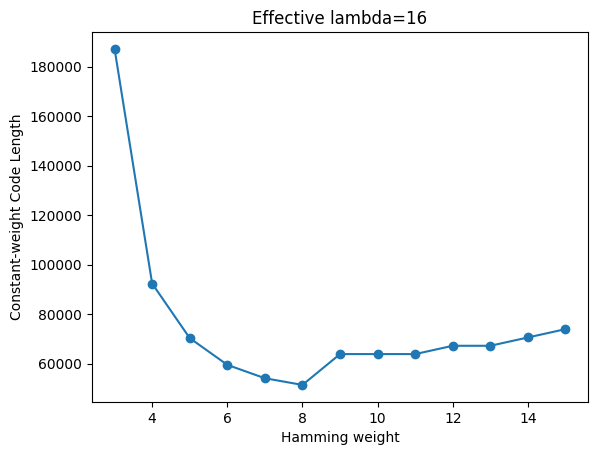

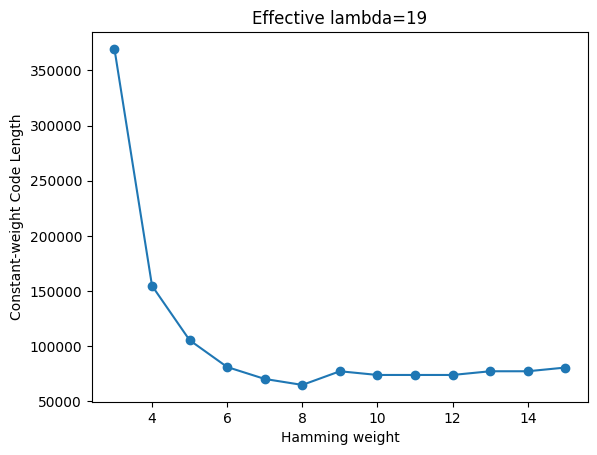

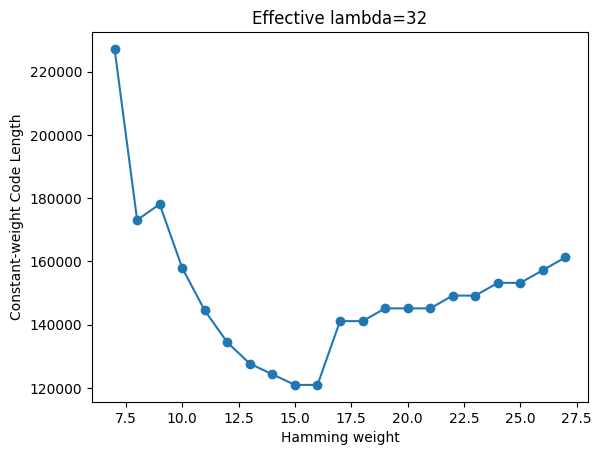

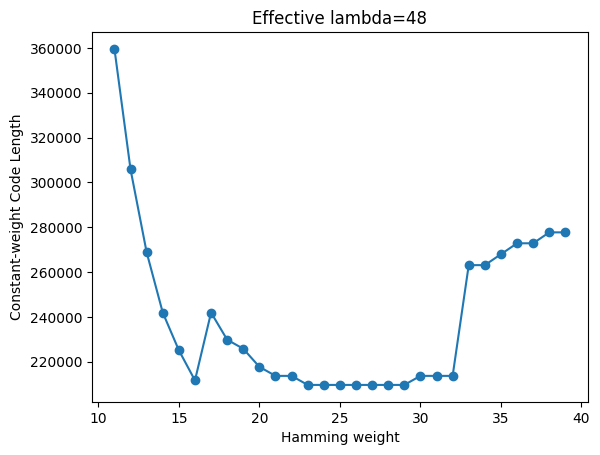

In [3]:
# 绘制给定有效安全参数下，不同汉明权重对应的常重码长度与乘积成本
import pandas as pd

# N_and_q_h 描述不同 log2(多项式模数) 对应的 (环维度N, 模数位数q)
N_and_q_h = [
        (12, 72),
        (13, 144),
        (13, 192),
        (13, 208),
        (14, 240),
        (14, 288),
        (14, 348),
    ]

# options 中给出若干 representative 的有效比特长度以及搜索的汉明权重区间
options = [
    (16,  3, 16),
    (19,  3, 16),
    (32,  7, 28),
    (48, 11, 40)
 ]

for _, (effective_lambda, start, end) in enumerate(options):
    hamming_weights = range(start, end)
    # 通过 log_find 计算最小常重码长度
    code_length = [log_find(effective_lambda, h) for h in hamming_weights]
    # 将长度乘以 (N, q) 的组合，得到通信+计算成本近似指标
    length_times_weight = [code_length[i]*N_and_q_h[ceil(log2(h))][1] * N_and_q_h[ceil(log2(h))][0] for i, h in enumerate(hamming_weights)]
    # 可选：直接绘制常重码长度曲线
    # plt.plot(hamming_weights, code_length)
    plt.plot(hamming_weights, length_times_weight, 'o-')
    opt_length = [effective_lambda for _ in hamming_weights] 
    # 可选：绘制理论最佳线作为对比
    # plt.plot(hamming_weights, opt_length)
    plt.title(f'Effective lambda={effective_lambda}')
    plt.xlabel('Hamming weight')
    plt.ylabel('Constant-weight Code Length')
    # 若需要留档，可将图保存为静态文件
    # plt.savefig(f'output-{effective_lambda}', dpi=500)
    plt.show()
    
    # 将表格数据导出 CSV，便于生成文中曲线
    pd.DataFrame({
        'HammingWeight' : list(hamming_weights),
        'CodeLength' : code_length,
        'CodeLengthWeight' : length_times_weight,
        'OptLength' : opt_length,
    }).to_csv(f'output-{effective_lambda}.csv', index=False)

枚举每个有效安全参数，对比不同汉明权重的代价，找出最优的配置。\
Finding the best Hamming weight for each effective bit-length.

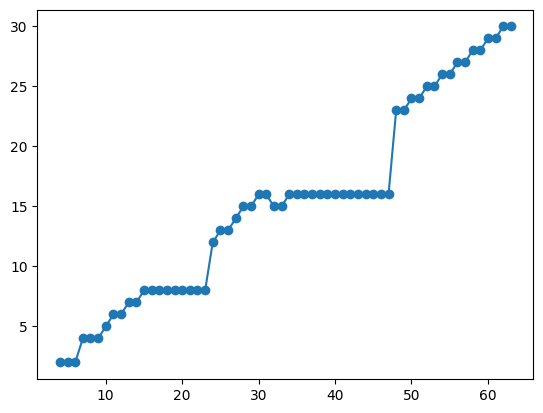

In [4]:
# 穷举每个有效比特长度的候选区间，选出计算复杂度最优的汉明权重
best_weights=[]
best_code_lengths=[]
effective_lambdas = range(4, 64)
for effective_lambda in effective_lambdas:
    # 根据经验，将搜索区间限定在 [λ/4, 3λ/4]，兼顾准确性与效率
    start=effective_lambda//4
    end=3*effective_lambda//4
    hamming_weights = range(start, end)
    # length_times_weight 存储 (成本指标, 汉明权重) 元组
    length_times_weight = [(log_find(effective_lambda, h)*N_and_q_h[ceil(log2(h))][1]*N_and_q_h[ceil(log2(h))][0],h) for h in hamming_weights]
    best_length, best_weight = min(length_times_weight)
    best_weights += [best_weight]
    best_code_lengths += [best_length]

# 绘制最优汉明权重曲线，展示随有效比特长度的变化趋势
plt.plot(effective_lambdas, best_weights, 'o-')
    
# 保存结果用于后续分析或论文中的表格
pd.DataFrame({
    'EffectiveBitlength' : list(effective_lambdas),
    'BestHammingWeight' : best_weights,
    'BestCodeLength' : best_code_lengths,
}).to_csv(f'best-hamming.csv', index=False)

In [5]:
# 打印最优权重序列，便于与其它算法对比
print(best_weights)

[2, 2, 2, 4, 4, 4, 5, 6, 6, 7, 7, 8, 8, 8, 8, 8, 8, 8, 8, 8, 12, 13, 13, 14, 15, 15, 16, 16, 15, 15, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 23, 23, 24, 24, 25, 25, 26, 26, 27, 27, 28, 28, 29, 29, 30, 30]


In [6]:
# 读取 experiments/results 目录中的所有指标 CSV，并拼接为一个 DataFrame
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def read_csvs(path):
    df = pd.DataFrame()
    all=[]
    for filename in os.listdir(path):
        if filename.endswith('.csv'):
            # 每个文件按 (metric, value) 的键值对存储，需要转置为单行
            all += [pd.read_csv(os.path.join(path, filename), names=['metric', 'value'], index_col=0).T]
    # 将所有实验轮次拼接在一起，ignore_index 确保索引重新编号
    df = pd.concat(all, ignore_index=True)
    
    return df

In [7]:
# 对聚合后的指标求均值、方差，并找出每个有效比特长度的最优汉明权重
cols = [
    'effective_lambda',
    'hw',
    'time_server',
]

df = read_csvs('../experiments/results')
df = df[cols]  # 只保留关注的字段
df_mean=df.groupby(['effective_lambda', 'hw']).mean()  # 每组参数的平均耗时
df_std=df.groupby(['effective_lambda', 'hw']).std()   # 同步记录标准差（可用于画误差条）
new_df = df_mean.reset_index()  # 将 groupby 索引还原为列，便于筛选
ans=[]
for el in range(4,62):
    filtered_df = new_df[new_df['effective_lambda']==el]
    # 取出该有效比特长度下服务器时间最小的组合
    ans.append(filtered_df[filtered_df['time_server'] == filtered_df['time_server'].min()])


plt.plot(list(pd.concat(ans)['hw']))  # 绘制最优汉明权重随 λ 的变化曲线
print(list(pd.concat(ans)['hw']))

FileNotFoundError: [Errno 2] No such file or directory: '../experiments/results'

In [ ]:
# 估算 Cuckoo 哈希最大负载的理论上界，供实验结果校验
from scipy.special import comb
from math import sqrt, log2, ceil

def load(n, m):
    return ceil(m/n + 1.3*sqrt(2*m*log2(n) / n))

In [ ]:
# 论文附录中的实验配置原始数据，方便复制到 pandas
"""
65536,8192,3145728,509
65536,8192,50331648,6597
65536,8192,805306368,100157
65536,16384,786432,93
65536,16384,3145728,281
65536,16384,12582912,938
""".split('\n')

In [ ]:
# 对上述参数逐项计算 load(n, m)，与模拟结果对照
xxx=[
    (8192,3145728,490),
    (8192,50331648,6541),
    (8192,805306368,99784),
    (16384,786432,85),
    (16384,3145728,262),
    (16384,12582912,916),
]

for n, m, t in xxx:
    print(n, m, load(n, m))

8192 3145728 514
8192 50331648 6664
8192 805306368 100383
16384 786432 96
16384 3145728 288
16384 12582912 959
